In [1]:
from pathlib import Path
import subprocess
import os

REPO_DIR = Path("/content/all-aml-gene-expression-classification")

if not REPO_DIR.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/feyzatesoglu/"
            "all-aml-gene-expression-classification.git",
            str(REPO_DIR)
        ],
        check=True
    )

os.chdir(REPO_DIR)
print("Çalışma klasörü:", Path.cwd())

Çalışma klasörü: /content/all-aml-gene-expression-classification


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "raw"

required_files = [
    "data_set_ALL_AML_train.csv",
    "data_set_ALL_AML_independent.csv",
    "actual.csv",
]

for filename in required_files:
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Dosya bulunamadı: {path}")

print("Veri klasörü:", DATA_DIR)

Veri klasörü: /content/all-aml-gene-expression-classification/data/raw


In [3]:
train_raw = pd.read_csv(DATA_DIR / "data_set_ALL_AML_train.csv")
test_raw = pd.read_csv(DATA_DIR / "data_set_ALL_AML_independent.csv")
labels_raw = pd.read_csv(DATA_DIR / "actual.csv")

for df in [train_raw, test_raw, labels_raw]:
    df.columns = df.columns.astype(str).str.strip()

print("Ham eğitim verisi:", train_raw.shape)
print("Ham test verisi:", test_raw.shape)
print("Etiket tablosu:", labels_raw.shape)

display(train_raw.iloc[:5, :8])
display(labels_raw.head())

Ham eğitim verisi: (7129, 78)
Ham test verisi: (7129, 70)
Etiket tablosu: (72, 2)


,Gene Description,Gene Accession Number,1,call,2,call.1,3,call.2
0,AFFX-BioB-5_at (endogenous control),AFFX-BioB-5_at,-214,A,-139,A,-76,A
1,AFFX-BioB-M_at (endogenous control),AFFX-BioB-M_at,-153,A,-73,A,-49,A
2,AFFX-BioB-3_at (endogenous control),AFFX-BioB-3_at,-58,A,-1,A,-307,A
3,AFFX-BioC-5_at (endogenous control),AFFX-BioC-5_at,88,A,283,A,309,A
4,AFFX-BioC-3_at (endogenous control),AFFX-BioC-3_at,-295,A,-264,A,-376,A


,patient,cancer
0,1,ALL
1,2,ALL
2,3,ALL
3,4,ALL
4,5,ALL


In [4]:
# Hasta sütunlarının adları "1", "2", "3" gibi sayılardan oluşuyor.
# Böylece gen açıklamaları ve call sütunları dışarıda kalıyor.
train_patient_columns = [
    column for column in train_raw.columns
    if column.isdigit()
]

test_patient_columns = [
    column for column in test_raw.columns
    if column.isdigit()
]

print("Eğitim hasta sayısı:", len(train_patient_columns))
print("Test hasta sayısı:", len(test_patient_columns))

# Gen probu kimliklerini satır indeksi olarak kullan.
train_expression = train_raw.set_index("Gene Accession Number")
test_expression = test_raw.set_index("Gene Accession Number")

# Yalnızca hastaların sayısal ifade ölçümlerini seç.
# .T ile satır ve sütunların yerini değiştir.
X_train = train_expression[train_patient_columns].apply(
    pd.to_numeric, errors="raise"
).T

X_test = test_expression[test_patient_columns].apply(
    pd.to_numeric, errors="raise"
).T

# Hasta numaralarını tam sayıya çevir.
X_train.index = X_train.index.astype(int)
X_test.index = X_test.index.astype(int)

X_train.index.name = "patient_id"
X_test.index.name = "patient_id"

# Gen probu kimliklerinin tekil olduğunu doğrula.
assert X_train.columns.is_unique, "Eğitimde tekrarlanan prob kimliği var."
assert X_test.columns.is_unique, "Testte tekrarlanan prob kimliği var."

# Eğitim ve testte aynı gen probları bulunmalı.
assert set(X_train.columns) == set(X_test.columns), (
    "Eğitim ve test gen probları eşleşmiyor."
)

# Test sütunlarını eğitimdeki gen sırasına getir.
X_test = X_test.loc[:, X_train.columns]

assert X_train.shape == (38, 7129)
assert X_test.shape == (34, 7129)

print("\nDüzenlenmiş eğitim verisi:", X_train.shape)
print("Düzenlenmiş test verisi:", X_test.shape)

display(X_train.iloc[:5, :5])

Eğitim hasta sayısı: 38
Test hasta sayısı: 34

Düzenlenmiş eğitim verisi: (38, 7129)
Düzenlenmiş test verisi: (34, 7129)


Gene Accession Number,AFFX-BioB-5_at,AFFX-BioB-M_at,AFFX-BioB-3_at,AFFX-BioC-5_at,AFFX-BioC-3_at
patient_id,,,,,
1,-214,-153,-58,88,-295
2,-139,-73,-1,283,-264
3,-76,-49,-307,309,-376
4,-135,-114,265,12,-419
5,-106,-125,-76,168,-230


In [5]:
# Ham etiket tablosunu koruyarak bir kopya oluştur.
labels = labels_raw.copy()

labels["patient"] = pd.to_numeric(labels["patient"], errors="raise")
assert labels["patient"].notna().all(), "Eksik hasta numarası var."
assert (labels["patient"] % 1 == 0).all(), "Hasta numarası tam sayı olmalı."

labels["patient"] = labels["patient"].astype(int)
labels["cancer"] = labels["cancer"].astype("string").str.strip().str.upper()

# Etiketlerin geçerliliğini kontrol et.
assert labels["patient"].is_unique, "Tekrarlanan hasta numarası var."
assert labels["cancer"].isin(["ALL", "AML"]).all(), "Geçersiz sınıf etiketi var."

labels = labels.set_index("patient")

assert X_train.index.is_unique
assert X_test.index.is_unique
assert X_train.index.intersection(X_test.index).empty, (
    "Eğitim ve testte ortak hasta var."
)

all_patients = X_train.index.union(X_test.index)
assert all_patients.difference(labels.index).empty, (
    "Bazı hastaların etiketi bulunamadı."
)

# Her hastanın etiketini X içindeki sıraya göre getir.
label_mapping = {"ALL": 0, "AML": 1}

y_train = labels.loc[X_train.index, "cancer"].map(label_mapping)
y_test = labels.loc[X_test.index, "cancer"].map(label_mapping)

y_train.name = "target"
y_test.name = "target"

assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

# Beklenen sınıf sayılarını doğrula.
assert y_train.value_counts().to_dict() == {0: 27, 1: 11}
assert y_test.value_counts().to_dict() == {0: 20, 1: 14}

summary = pd.DataFrame({
    "Veri": ["Eğitim", "Test"],
    "Hasta sayısı": [len(y_train), len(y_test)],
    "ALL (0)": [(y_train == 0).sum(), (y_test == 0).sum()],
    "AML (1)": [(y_train == 1).sum(), (y_test == 1).sum()],
})

display(summary)
print("Hasta–etiket eşleştirmesi ve sınıf sayıları doğrulandı.")

,Veri,Hasta sayısı,ALL (0),AML (1)
0,Eğitim,38,27,11
1,Test,34,20,14


Hasta–etiket eşleştirmesi ve sınıf sayıları doğrulandı.


In [6]:
def data_quality_summary(X):
    values = X.to_numpy(dtype=float)
    finite_mask = np.isfinite(values)
    finite_values = values[finite_mask]

    return {
        "Hasta sayısı": X.shape[0],
        "Gen probu sayısı": X.shape[1],
        "Eksik değer (NaN)": int(np.isnan(values).sum()),
        "Sonsuz değer (INF)": int(np.isinf(values).sum()),
        "Negatif değer": int(((values < 0) & finite_mask).sum()),
        "Negatif değer (%)": round(
            100 * ((values < 0) & finite_mask).sum() / values.size, 2
        ),
        "Sıfır değer": int((values == 0).sum()),
        "En küçük sonlu değer": (
            finite_values.min() if finite_values.size else np.nan
        ),
        "Medyan sonlu değer": (
            np.median(finite_values) if finite_values.size else np.nan
        ),
        "En büyük sonlu değer": (
            finite_values.max() if finite_values.size else np.nan
        ),
    }


quality_table = pd.DataFrame({
    "Eğitim": data_quality_summary(X_train),
    "Test": data_quality_summary(X_test),
})

display(quality_table)

,Eğitim,Test
Hasta sayısı,38.00,34.00
Gen probu sayısı,7129.00,7129.00
Eksik değer (NaN),0.00,0.00
Sonsuz değer (INF),0.00,0.00
Negatif değer,77175.00,69999.00
Negatif değer (%),28.49,28.88
Sıfır değer,738.00,877.00
En küçük sonlu değer,-28400.00,-26775.00
Medyan sonlu değer,127.00,114.00
En büyük sonlu değer,61228.00,71369.00


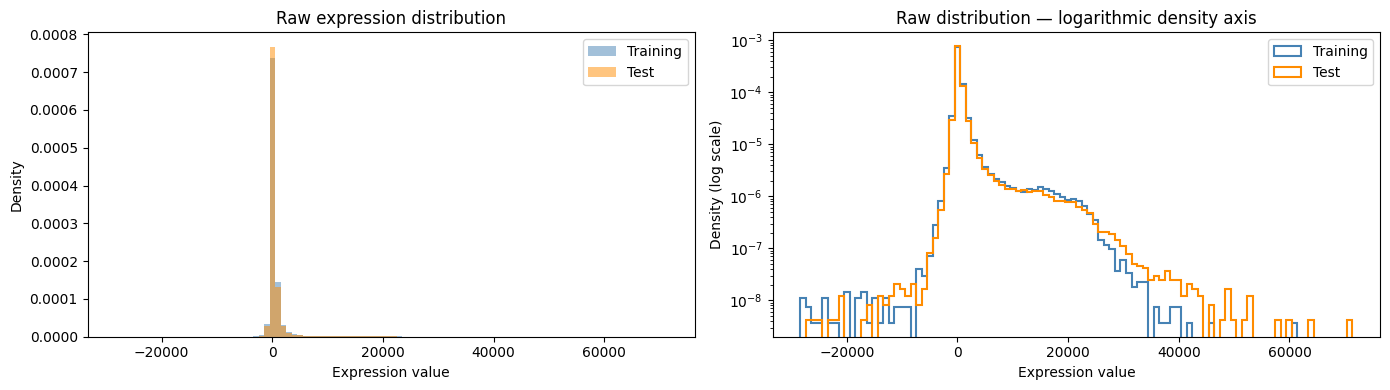

In [7]:
import matplotlib.pyplot as plt

train_values = X_train.to_numpy(dtype=float).ravel()
test_values = X_test.to_numpy(dtype=float).ravel()

# İki veri setini aynı histogram aralıklarıyla karşılaştır.
bins = np.linspace(
    min(train_values.min(), test_values.min()),
    max(train_values.max(), test_values.max()),
    101
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for values, label, color in [
    (train_values, "Training", "steelblue"),
    (test_values, "Test", "darkorange")
]:
    axes[0].hist(
        values,
        bins=bins,
        density=True,
        alpha=0.5,
        label=label,
        color=color
    )

axes[0].set_title("Raw expression distribution")
axes[0].set_xlabel("Expression value")
axes[0].set_ylabel("Density")
axes[0].legend()

# Kuyrukları görünür kılmak için aynı dağılımı
# logaritmik Y ekseniyle de göster.
for values, label, color in [
    (train_values, "Training", "steelblue"),
    (test_values, "Test", "darkorange")
]:
    axes[1].hist(
        values,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=1.5,
        label=label,
        color=color
    )

axes[1].set_yscale("log")
axes[1].set_title("Raw distribution — logarithmic density axis")
axes[1].set_xlabel("Expression value")
axes[1].set_ylabel("Density (log scale)")
axes[1].legend()

plt.tight_layout()
plt.show()

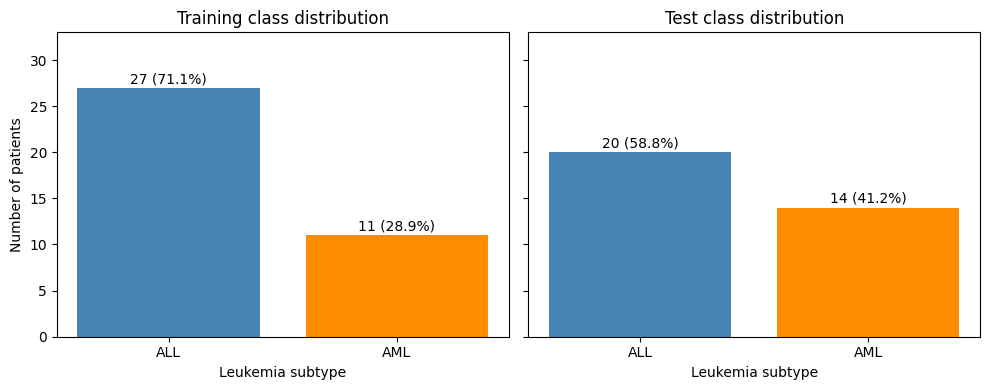

In [9]:
class_counts = pd.DataFrame({
    "Training": y_train.value_counts().reindex([0, 1], fill_value=0),
    "Test": y_test.value_counts().reindex([0, 1], fill_value=0)
})

class_counts.index = ["ALL", "AML"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, dataset in zip(axes, ["Training", "Test"]):
    counts = class_counts[dataset]
    percentages = counts / counts.sum() * 100

    bars = ax.bar(
        counts.index,
        counts.values,
        color=["steelblue", "darkorange"]
    )

    for bar, count, percentage in zip(bars, counts, percentages):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f"{count} ({percentage:.1f}%)",
            ha="center"
        )

    ax.set_title(f"{dataset} class distribution")
    ax.set_xlabel("Leukemia subtype")
    ax.set_ylim(0, class_counts.to_numpy().max() + 6)

axes[0].set_ylabel("Number of patients")

plt.tight_layout()
plt.show()

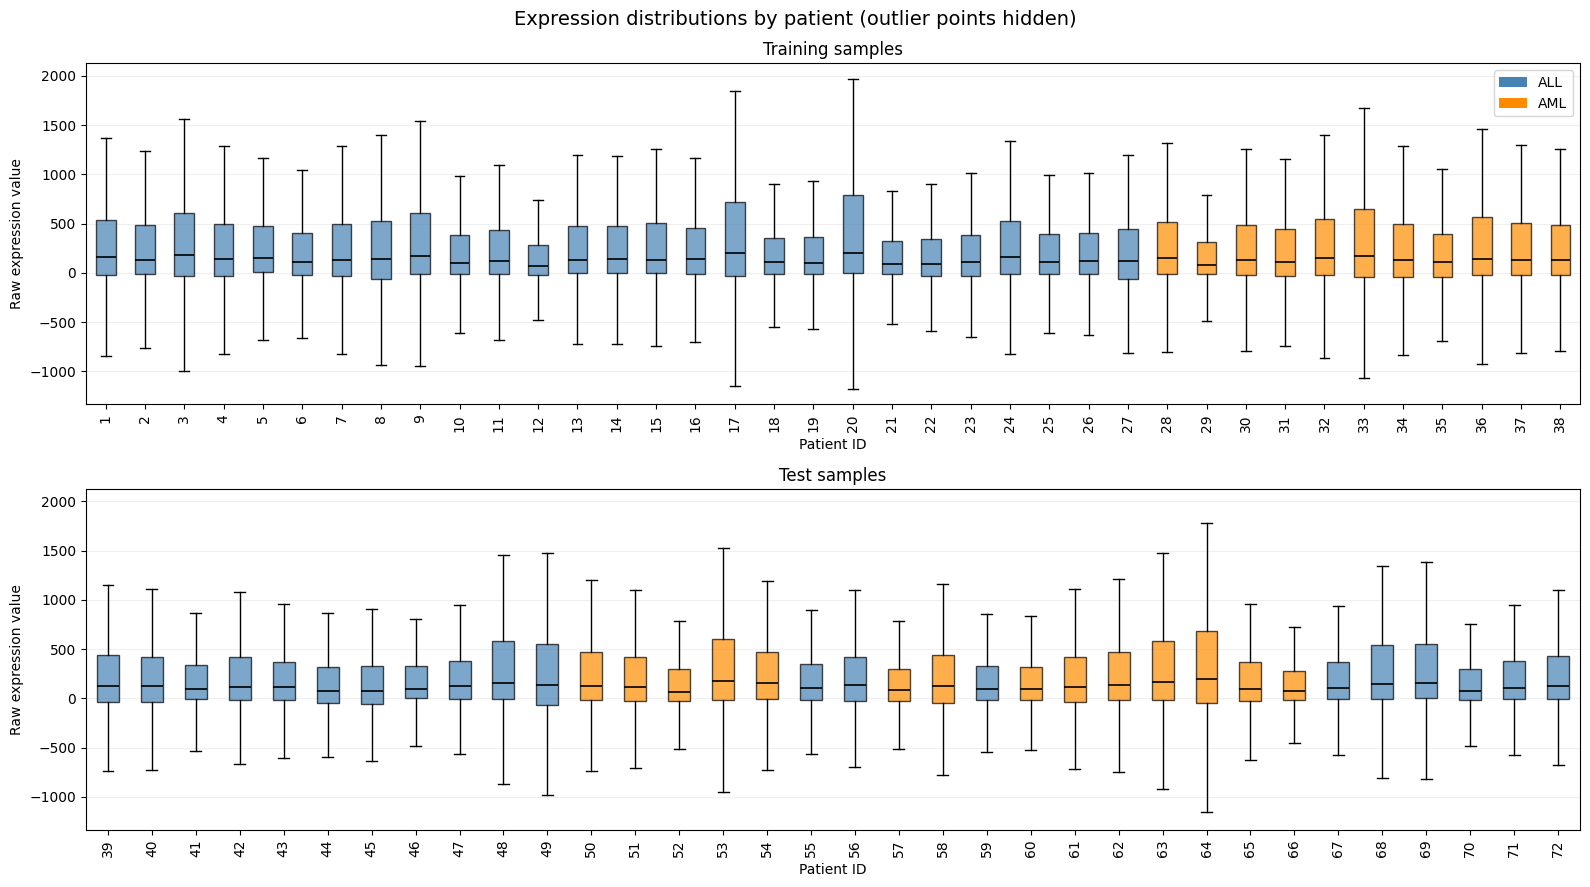

In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

colors = {0: "steelblue", 1: "darkorange"}

fig, axes = plt.subplots(
    2, 1, figsize=(16, 9), sharey=True
)

for ax, X, y, title in [
    (axes[0], X_train, y_train, "Training samples"),
    (axes[1], X_test, y_test, "Test samples")
]:
    # Hasta numarasına göre sırala; etiketleri aynı sıraya getir.
    X_plot = X.sort_index()
    y_plot = y.loc[X_plot.index]

    positions = np.arange(1, len(X_plot) + 1)

    boxes = ax.boxplot(
        X_plot.to_numpy().T,
        positions=positions,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.2}
    )

    for box, label in zip(boxes["boxes"], y_plot):
        box.set_facecolor(colors[int(label)])
        box.set_alpha(0.7)

    ax.set_xticks(positions)
    ax.set_xticklabels(X_plot.index, rotation=90)
    ax.set_title(title)
    ax.set_xlabel("Patient ID")
    ax.set_ylabel("Raw expression value")
    ax.grid(axis="y", alpha=0.2)

axes[0].legend(handles=[
    Patch(facecolor=colors[0], label="ALL"),
    Patch(facecolor=colors[1], label="AML")
])

fig.suptitle(
    "Expression distributions by patient (outlier points hidden)",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [11]:
def patient_summary(X, y):
    q1 = X.quantile(0.25, axis=1)
    q3 = X.quantile(0.75, axis=1)

    return pd.DataFrame({
        "Class": y.loc[X.index].map({0: "ALL", 1: "AML"}),
        "Median": X.median(axis=1),
        "Q1": q1,
        "Q3": q3,
        "IQR": q3 - q1,
        "Minimum": X.min(axis=1),
        "Maximum": X.max(axis=1),
        "Negative (%)": (X < 0).mean(axis=1) * 100,
    })


train_patient_summary = patient_summary(X_train, y_train)
test_patient_summary = patient_summary(X_test, y_test)

print("Eğitim — yayılımı (IQR) en yüksek 5 hasta:")
display(
    train_patient_summary.sort_values("IQR", ascending=False)
    .head(5).round(2)
)

print("Eğitim — medyanı en düşük ve en yüksek hastalar:")
median_sorted = train_patient_summary.sort_values("Median")
display(pd.concat([
    median_sorted.head(3),
    median_sorted.tail(3)
]).round(2))

print("Test — yayılımı (IQR) en yüksek 5 hasta:")
display(
    test_patient_summary.sort_values("IQR", ascending=False)
    .head(5).round(2)
)

Eğitim — yayılımı (IQR) en yüksek 5 hasta:


,Class,Median,Q1,Q3,IQR,Minimum,Maximum,Negative (%)
patient_id,,,,,,,,
20,ALL,198.0,-1.0,788.0,789.0,-13838,27358,25.05
17,ALL,201.0,-33.0,718.0,751.0,-19523,28952,28.88
33,AML,170.0,-38.0,649.0,687.0,-27811,32946,29.36
3,ALL,177.0,-31.0,610.0,641.0,-27182,28056,28.77
9,ALL,166.0,-14.0,609.0,623.0,-25171,23602,27.03


Eğitim — medyanı en düşük ve en yüksek hastalar:


,Class,Median,Q1,Q3,IQR,Minimum,Maximum,Negative (%)
patient_id,,,,,,,,
12,ALL,70.0,-25.0,281.0,306.0,-15256,30546,31.32
29,AML,82.0,-13.0,309.0,322.0,-9501,30354,28.18
21,ALL,91.0,-14.0,323.0,337.0,-7397,33548,28.50
3,ALL,177.0,-31.0,610.0,641.0,-27182,28056,28.77
20,ALL,198.0,-1.0,788.0,789.0,-13838,27358,25.05
17,ALL,201.0,-33.0,718.0,751.0,-19523,28952,28.88


Test — yayılımı (IQR) en yüksek 5 hasta:


,Class,Median,Q1,Q3,IQR,Minimum,Maximum,Negative (%)
patient_id,,,,,,,,
64,AML,195.0,-51.0,683.0,734.0,-26258,71369,30.06
53,AML,171.0,-20.0,599.0,619.0,-20698,37936,27.55
49,ALL,139.0,-65.0,552.0,617.0,-26775,29500,32.53
63,AML,162.0,-21.0,578.0,599.0,-20782,31585,27.90
48,ALL,158.0,-6.0,577.0,583.0,-16945,25231,25.80


,Eğitim,Test
20 altındaki ölçüm (%),32.37,33.11
16000 üstündeki ölçüm (%),0.86,0.80


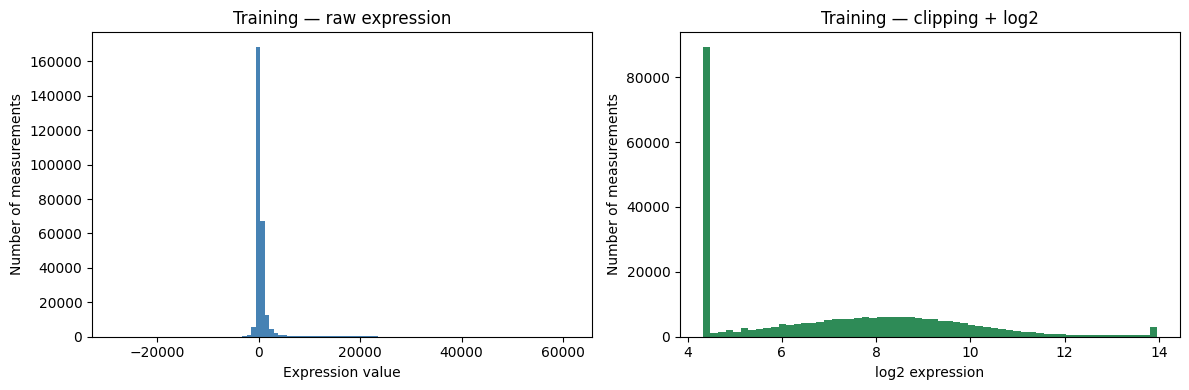

In [12]:
LOWER_BOUND = 20
UPPER_BOUND = 16000

# Ham X_train ve X_test korunuyor.
X_train_log = np.log2(
    X_train.clip(lower=LOWER_BOUND, upper=UPPER_BOUND)
)

X_test_log = np.log2(
    X_test.clip(lower=LOWER_BOUND, upper=UPPER_BOUND)
)

def clipping_summary(X):
    values = X.to_numpy()

    return {
        "20 altındaki ölçüm (%)": 100 * (values < LOWER_BOUND).mean(),
        "16000 üstündeki ölçüm (%)": 100 * (values > UPPER_BOUND).mean(),
    }

display(pd.DataFrame({
    "Eğitim": clipping_summary(X_train),
    "Test": clipping_summary(X_test),
}).round(2))

assert np.isfinite(X_train_log.to_numpy()).all()
assert np.isfinite(X_test_log.to_numpy()).all()

# Dönüşüm etkisini eğitim verisinde incele.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    X_train.to_numpy().ravel(),
    bins=100,
    color="steelblue"
)
axes[0].set_title("Training — raw expression")
axes[0].set_xlabel("Expression value")
axes[0].set_ylabel("Number of measurements")

axes[1].hist(
    X_train_log.to_numpy().ravel(),
    bins=60,
    color="seagreen"
)
axes[1].set_title("Training — clipping + log2")
axes[1].set_xlabel("log2 expression")
axes[1].set_ylabel("Number of measurements")

plt.tight_layout()
plt.show()

PCA'da kullanılan prob sayısı: 6638
Eğitimde sabit kalan prob sayısı: 491
PC1 açıklanan varyans: %11.81
PC2 açıklanan varyans: %8.87
İlk iki bileşen toplamı: %20.68


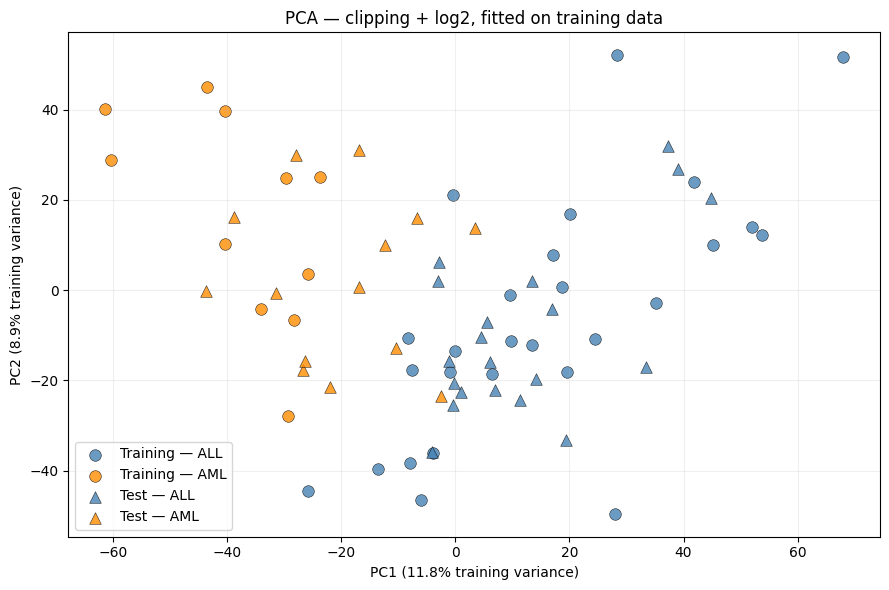

In [13]:
from sklearn.decomposition import PCA

# Eğitimde sabit kalan problar PCA'ya bilgi katmaz.
variable_probes = X_train_log.nunique(axis=0) > 1

X_train_pca_input = X_train_log.loc[:, variable_probes]
X_test_pca_input = X_test_log.loc[:, variable_probes]

print("PCA'da kullanılan prob sayısı:", variable_probes.sum())
print("Eğitimde sabit kalan prob sayısı:", (~variable_probes).sum())

# PCA eksenlerini yalnızca eğitim verisinden öğren.
pca = PCA(n_components=2, svd_solver="full")

train_coordinates = pca.fit_transform(X_train_pca_input)
test_coordinates = pca.transform(X_test_pca_input)

variance = pca.explained_variance_ratio_ * 100

print(f"PC1 açıklanan varyans: %{variance[0]:.2f}")
print(f"PC2 açıklanan varyans: %{variance[1]:.2f}")
print(f"İlk iki bileşen toplamı: %{variance.sum():.2f}")

fig, ax = plt.subplots(figsize=(9, 6))

for coordinates, y, split, marker in [
    (train_coordinates, y_train, "Training", "o"),
    (test_coordinates, y_test, "Test", "^")
]:
    for label, name, color in [
        (0, "ALL", "steelblue"),
        (1, "AML", "darkorange")
    ]:
        mask = y.to_numpy() == label

        ax.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            label=f"{split} — {name}",
            color=color,
            marker=marker,
            s=70,
            alpha=0.8,
            edgecolors="black",
            linewidths=0.4
        )

ax.set_xlabel(f"PC1 ({variance[0]:.1f}% training variance)")
ax.set_ylabel(f"PC2 ({variance[1]:.1f}% training variance)")
ax.set_title("PCA — clipping + log2, fitted on training data")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

30 PCA bileşeninin açıkladığı toplam varyans: %91.49


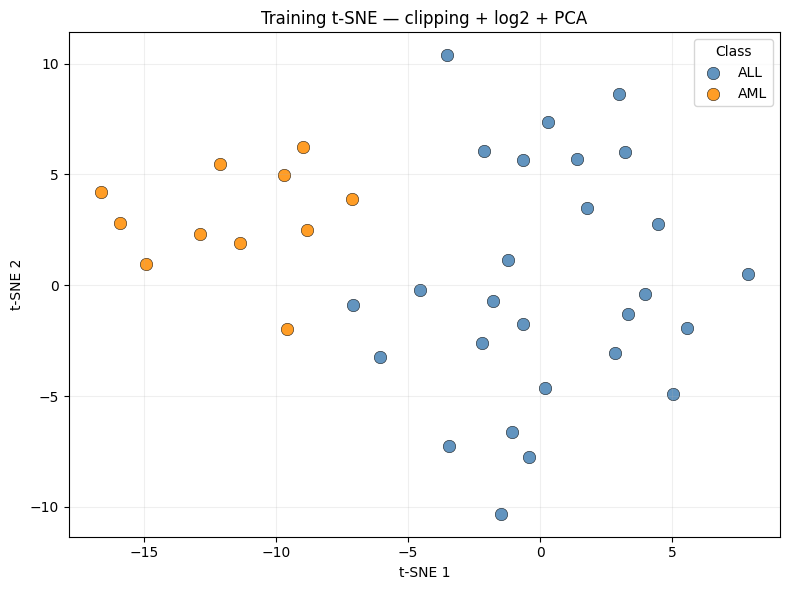

In [14]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Önceki hücrede hazırlanan, sabit probları çıkarılmış eğitim verisi.
# 38 hasta için en fazla 37 anlamlı PCA bileşeni kullanılabilir.
n_components = min(
    30,
    X_train_pca_input.shape[0] - 1,
    X_train_pca_input.shape[1]
)

pca_for_tsne = PCA(n_components=n_components, svd_solver="full")
X_train_reduced = pca_for_tsne.fit_transform(X_train_pca_input)

print(
    f"{n_components} PCA bileşeninin açıkladığı toplam varyans: "
    f"%{100 * pca_for_tsne.explained_variance_ratio_.sum():.2f}"
)

tsne = TSNE(
    n_components=2,
    perplexity=10,
    init="pca",
    learning_rate="auto",
    max_iter=1500,
    random_state=42
)

# Sınıf etiketleri dönüşümde kullanılmaz; sadece renklendirme içindir.
tsne_coordinates = tsne.fit_transform(X_train_reduced)

fig, ax = plt.subplots(figsize=(8, 6))

for label, name, color in [
    (0, "ALL", "steelblue"),
    (1, "AML", "darkorange")
]:
    mask = y_train.to_numpy() == label
    ax.scatter(
        tsne_coordinates[mask, 0],
        tsne_coordinates[mask, 1],
        label=name,
        color=color,
        s=80,
        alpha=0.85,
        edgecolors="black",
        linewidths=0.4
    )

ax.set_title("Training t-SNE — clipping + log2 + PCA")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.legend(title="Class")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()